# 01 · Factor model: what explains a return?

A time-series factor regression asks how much of an asset's return is compensation for known, cheap-to-buy exposures, and how much is left over:

$$r_t - r_{f,t} = \alpha + \beta_{M}\,\text{Mkt}_t + \beta_{S}\,\text{SMB}_t + \beta_{H}\,\text{HML}_t + \beta_{R}\,\text{RMW}_t + \beta_{C}\,\text{CMA}_t + \beta_{U}\,\text{Mom}_t + \varepsilon_t$$

| Factor | Long | Short |
|---|---|---|
| Mkt-RF | the market | T-bills |
| SMB (size) | small caps | large caps |
| HML (value) | high book-to-market | low book-to-market |
| RMW (profitability) | robust operating profitability | weak |
| CMA (investment) | conservative asset growth | aggressive |
| Mom (momentum) | past 12-1 month winners | losers |

The betas say *what kind of investor* the asset behaves like; **alpha** is the average return none of those exposures explain. An asset manager pays factor-ETF fees for the betas and active fees only for alpha, so this split is the first question asked of any fund or strategy.

**Two studies:**
- **Part A, Berkshire Hathaway 1990–2026.** A known answer to check the tool against: the literature (Frazzini, Kabiller and Pedersen, *Buffett's Alpha*) finds Berkshire is a levered bet on cheap, safe, high-quality stocks, and that these factors absorb much of its alpha.
- **Part B, the SaaS Valuation Engine's signal.** My [valuation engine](https://github.com/ranabrahami/saas-valuation-engine) ranks 18 software companies as "cheap for their growth". Its point-in-time backtest found a 12-month rank IC of 0.21. Is that alpha, or a disguised factor bet?

**Data.** Factors: Kenneth French's data library (monthly, US). Prices: Yahoo Finance dividend-adjusted closes. Standard errors: Newey-West (HAC), because monthly returns are heteroskedastic and, for overlapping portfolios, autocorrelated.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quant_research.data import french, prices
from quant_research.factors import model, portfolios as pf

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

f = french.factors()
print(f"Factors: {f.index.min():%Y-%m} to {f.index.max():%Y-%m}, {len(f)} months")

Factors: 1963-07 to 2026-09, 759 months


## Part A · Berkshire Hathaway

Monthly total returns of the A shares from 1990 (a long sample, after Berkshire's early hyper-growth), less the T-bill rate.

In [2]:
brk = model.excess(prices.monthly_total_returns("BRK-A"), f)
brk = brk[brk.index >= "1990-01-01"]
fits = {name: model.fit(brk, f, terms) for name, terms in
        {"CAPM": model.CAPM, "FF3": ["Mkt-RF", "SMB", "HML"], "FF5 + Mom": model.FF5_MOM}.items()}
full = fits["FF5 + Mom"]
print(f"{full.n} months, {full.start:%Y-%m} to {full.end:%Y-%m}, Newey-West lags {full.lags}, R² {full.r2:.2f}")
full.summary()

441 months, 1990-01 to 2026-09, Newey-West lags 5, R² 0.36


,factor,coef,se,t,p
const,Alpha,0.036,0.026,1.381,0.167
Mkt-RF,Market,0.732,0.076,9.628,0.000
SMB,Size (small minus big),-0.358,0.104,-3.459,0.001
HML,Value (high minus low B/M),0.521,0.112,4.651,0.000
RMW,Profitability (robust minus weak),0.243,0.084,2.911,0.004
CMA,Investment (conservative minus aggressive),-0.100,0.169,-0.589,0.556
Mom,Momentum (up minus down),-0.016,0.049,-0.333,0.739


In [3]:
pd.DataFrame({name: {"alpha / yr": r.alpha_annual, "t(alpha)": r.alpha_t, "R²": r.r2}
              for name, r in fits.items()}).T

,alpha / yr,t(alpha),R²
CAPM,0.060,2.139,0.214
FF3,0.043,1.749,0.352
FF5 + Mom,0.036,1.381,0.362


**Reading the loadings.**
- **Market beta well below 1.** Berkshire carries less market risk than the index, consistent with its tilt to stable businesses.
- **Negative size.** It behaves like a large cap, which it is.
- **Positive value and profitability, both significant.** The "cheap, high-quality" style the literature describes.
- **Alpha shrinks as factors are added**, and in the full model it is no longer statistically different from zero. That doesn't say Buffett lacked skill: he picked these exposures decades before they were written down as factors. It says that today the style can be bought for much less than a stock picker's fee.

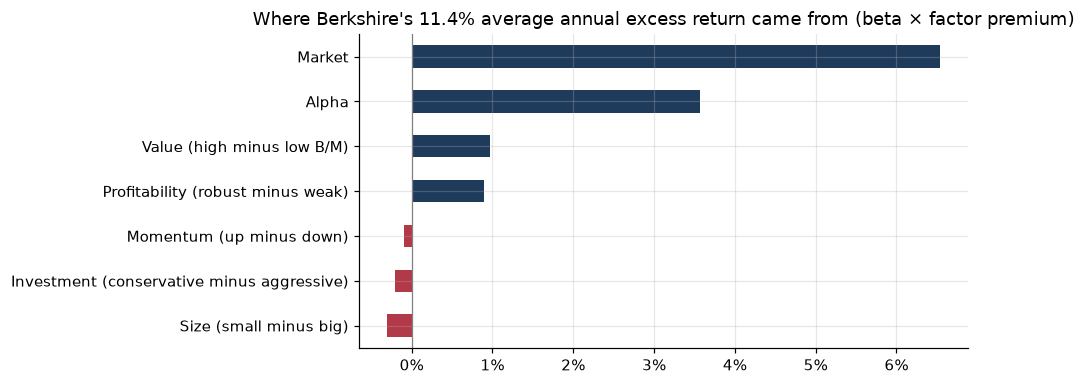

In [4]:
attr = model.attribution(brk, f, full)
total = attr.pop("Total (actual average excess return)")
ax = attr.sort_values().plot.barh(color=["#b23a48" if v < 0 else "#1f3b5c" for v in attr.sort_values()])
ax.axvline(0, color="grey", lw=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title(f"Where Berkshire's {total:.1%} average annual excess return came from (beta × factor premium)")
plt.tight_layout()

### Has the alpha decayed?

A 60-month rolling regression shows how the exposures and the unexplained return moved over time. Each point uses only the previous five years.

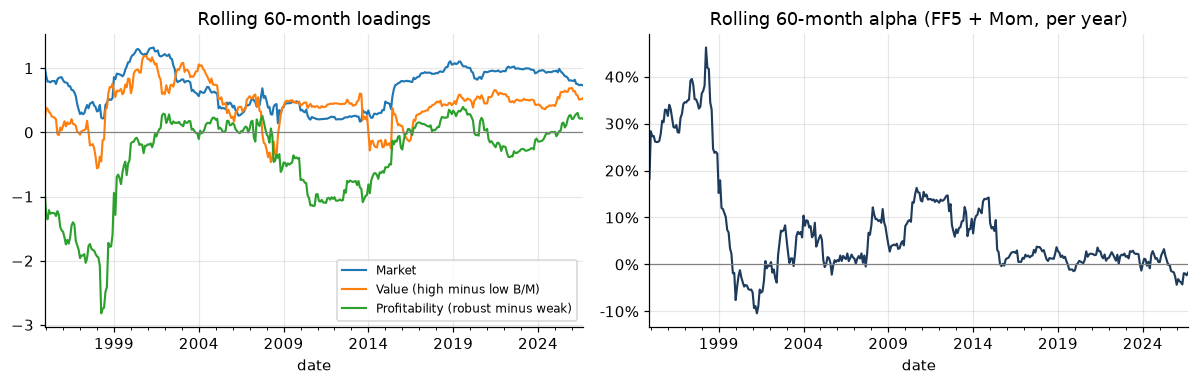

In [5]:
roll = model.rolling_exposures(brk, f, window=60)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
roll[["Mkt-RF", "HML", "RMW"]].rename(columns=model.NAMES).plot(ax=axes[0], lw=1.4)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title("Rolling 60-month loadings")
axes[0].legend(fontsize=8)
roll["alpha_annual"].plot(ax=axes[1], color="#1f3b5c", lw=1.4)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].set_title("Rolling 60-month alpha (FF5 + Mom, per year)")
plt.tight_layout()

In [6]:
halves = {f"{a}–{b}": model.fit(brk[a:b], f) for a, b in (("1990", "2007"), ("2008", "2026"))}
pd.DataFrame({k: {"months": r.n, "alpha / yr": r.alpha_annual, "t(alpha)": r.alpha_t, "R²": r.r2}
              for k, r in halves.items()}).T

,months,alpha / yr,t(alpha),R²
1990–2007,216.000,0.050,1.096,0.318
2008–2026,225.000,0.019,0.700,0.443


The rolling alpha fell from 30%+ a year in the late 1990s to roughly zero over the last decade, and the split halves show the same decline: a size problem (it is hard to move a trillion-dollar balance sheet into small mispricings) and a crowded style (value and quality are now packaged in cheap ETFs). Neither half is significant on its own, which is the honest limit of monthly data: alpha of a few percent a year with ~16% tracking error needs decades to prove.

**Check on the tool:** the sign and size of every loading match the published findings, so the regression is wired correctly and can be pointed at something new.

## Part B · The valuation engine's signal

### From a ranking to a portfolio

Each quarter-end from March 2023, the engine scored the 18 companies using only filings and prices public that day (exported from its backtest, `data/engine_signals.csv`). The portfolio:
- **Long** the cheapest third (6 names), **short** the most expensive third (6 names), equal weights.
- Returns start the month *after* the signal date, so nothing from before the signal leaks in.

### First question: when does the signal pay?

Before choosing how long to hold, look at the long-minus-short return in each month after the signal, across all 15 signal dates.

15 signal dates 2023-03-31 to 2026-09-30, 18 companies


,mean,obs,annualized
window,,,
months 1–3,-0.001,42,-0.010
4–6,0.006,39,0.067
7–9,0.011,36,0.130
10–12,0.022,33,0.266


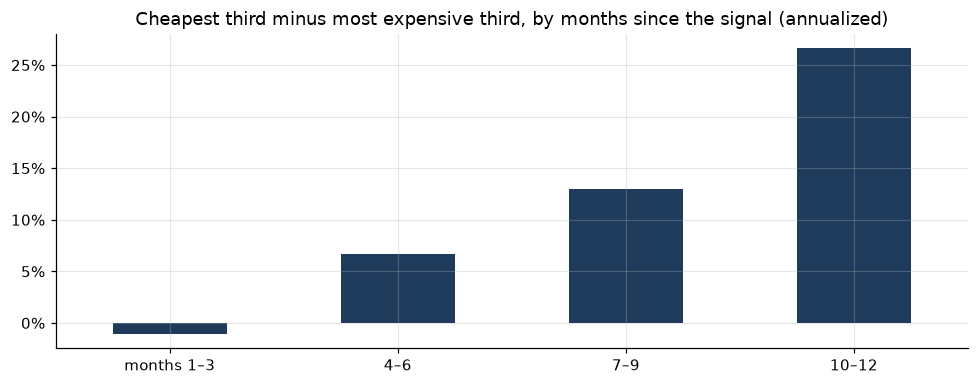

In [7]:
sig = pd.read_csv("../data/engine_signals.csv")
rets = pd.concat({t: prices.monthly_total_returns(t, start="2022-01-01") for t in sorted(sig.ticker.unique())}, axis=1)
rets = rets[rets.index <= f.index.max()]           # keep months the factor data covers
print(f"{sig.date.nunique()} signal dates {sig.date.min()} to {sig.date.max()}, {sig.ticker.nunique()} companies")

ev = pf.event_time(sig, rets, "score")
ev["window"] = pd.cut(ev["k"], [0, 3, 6, 9, 12], labels=["months 1–3", "4–6", "7–9", "10–12"])
by_window = ev.groupby("window", observed=True)["long_short"].agg(mean="mean", obs="count")
by_window["annualized"] = by_window["mean"] * 12
ax = by_window["annualized"].plot.bar(color="#1f3b5c", rot=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_title("Cheapest third minus most expensive third, by months since the signal (annualized)")
ax.set_xlabel("")
plt.tight_layout()
by_window

**The payoff arrives late.** Almost nothing happens in the first quarter; most of the return comes 7–12 months out. This matches the engine's backtest (6-month IC 0.08 versus 12-month IC 0.21) and the economics of the signal: a company that is cheap for its growth needs a few earnings reports before the market re-rates it.

This matters for portfolio design. A portfolio rebalanced every quarter keeps only months 1–3, the weakest part of the payoff, and throws the rest away.

### Two designs

- **Quarterly holding:** each portfolio is held until the next signal date (3 months).
- **12-month overlapping holding** (Jegadeesh and Titman, 1993): each quarter starts a new portfolio held for 12 months, and each month's return averages the up-to-four portfolios still held. This matches the holding period to the signal's horizon. Overlap makes consecutive months related, which the Newey-West errors account for.

In [8]:
designs = {"Quarterly holding": None, "12-month overlapping": 12}
ls = {name: pf.long_short_returns(sig, rets, "score", holding_months=h) for name, h in designs.items()}

summary = pd.DataFrame({name: {"months": len(d), "long / yr": d["long"].mean() * 12, "short / yr": d["short"].mean() * 12,
                               "long − short / yr": d["long_short"].mean() * 12,
                               "volatility": d["long_short"].std() * 12 ** 0.5,
                               "Sharpe": d["long_short"].mean() / d["long_short"].std() * 12 ** 0.5}
                        for name, d in ls.items()}).T
summary

,months,long / yr,short / yr,long − short / yr,volatility,Sharpe
Quarterly holding,42.000,0.196,0.207,-0.010,0.327,-0.032
12-month overlapping,42.000,0.246,0.188,0.057,0.276,0.208


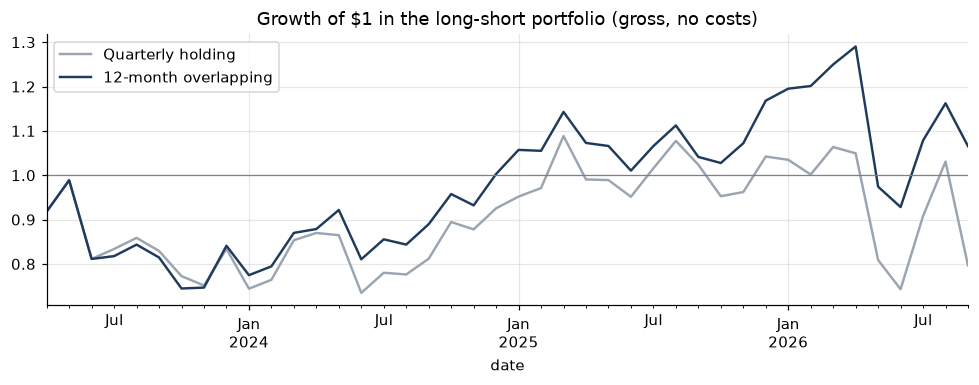

In [9]:
fig, ax = plt.subplots()
for (name, d), c in zip(ls.items(), ["#9aa5b1", "#1f3b5c"]):
    (1 + d["long_short"]).cumprod().plot(ax=ax, label=name, color=c, lw=1.6)
ax.axhline(1, color="grey", lw=0.8)
ax.set_title("Growth of $1 in the long-short portfolio (gross, no costs)")
ax.legend()
plt.tight_layout()

### Is it alpha?

Regress the 12-month design on progressively richer factor models. A long-short portfolio is already self-financing, so its return needs no risk-free adjustment.

In [10]:
main = ls["12-month overlapping"]["long_short"]
models = {"CAPM": model.CAPM, "FF3": ["Mkt-RF", "SMB", "HML"], "FF5 + Mom": model.FF5_MOM}
compare = pd.DataFrame({
    f"{design} · {m}": {"alpha / yr": (r := model.fit(d["long_short"], f, terms)).alpha_annual,
                        "t(alpha)": r.alpha_t, "R²": r.r2}
    for design, d in ls.items() for m, terms in models.items()}).T
compare

,alpha / yr,t(alpha),R²
Quarterly holding · CAPM,0.064,0.561,0.037
Quarterly holding · FF3,0.159,1.308,0.187
Quarterly holding · FF5 + Mom,0.133,1.157,0.420
12-month overlapping · CAPM,0.114,1.080,0.030
12-month overlapping · FF3,0.206,1.972,0.187
12-month overlapping · FF5 + Mom,0.175,1.638,0.333


In [11]:
eng = model.fit(main, f)
print(f"12-month overlapping, FF5 + Mom: {eng.n} months, Newey-West lags {eng.lags}, residual vol {eng.residual_vol:.0%}")
eng.summary()

12-month overlapping, FF5 + Mom: 42 months, Newey-West lags 3, residual vol 23%


,factor,coef,se,t,p
const,Alpha,0.175,0.107,1.638,0.101
Mkt-RF,Market,-0.403,0.409,-0.985,0.325
SMB,Size (small minus big),0.905,0.334,2.708,0.007
HML,Value (high minus low B/M),0.274,0.382,0.717,0.473
RMW,Profitability (robust minus weak),0.729,0.563,1.296,0.195
CMA,Investment (conservative minus aggressive),-0.851,0.454,-1.872,0.061
Mom,Momentum (up minus down),-0.352,0.330,-1.066,0.286


In [12]:
eng_attr = model.attribution(main, f, eng)
pd.DataFrame({"factor premium / yr, same months": (f.loc[main.index, model.FF5_MOM].mean() * 12)
                  .rename(index=model.NAMES),
              "contribution / yr (beta × premium)": eng_attr.drop(["Alpha", "Total (actual average excess return)"])})

,"factor premium / yr, same months",contribution / yr (beta × premium)
Market,0.153,-0.062
Size (small minus big),-0.051,-0.046
Value (high minus low B/M),0.029,0.008
Profitability (robust minus weak),-0.043,-0.031
Investment (conservative minus aggressive),-0.046,0.039
Momentum (up minus down),0.072,-0.025


**Reading the result.**
- **Alpha is positive under every model and grows as factors are added.** The table above shows why: in 2023–26 the market rose about 15% a year while small caps, profitability and momentum ran against the portfolio's tilts. Its exposures *cost* it return, so once they are accounted for, the stock selection looks better than the raw +6% spread.
- **The one clear exposure is size.** The cheap names are the smaller companies in the group, so the portfolio behaves like a small-cap bet. Small caps lagged in this period; in a period when they win, part of the raw spread would be size, not stock picking.
- **Momentum is negative but not significant.** The signal tends to buy recent losers; at the 12-month horizon that isn't what drives the return.
- **It is not statistically significant.** A t-statistic around 1.6 means a result this large would appear by luck fairly often. The noise is the problem: residual volatility is above 20% a year because 6 stocks per side in one sector is a concentrated bet. And an alpha of 17% a year is far above what any persistent strategy earns; it is a point estimate from 42 noisy months, not an expected return.

How long would the track record need to be? If the alpha and residual volatility stayed at these values, t ≈ α·√years / σ, so reaching t = 2 takes:

In [13]:
years_needed = (2 * eng.residual_vol / eng.alpha_annual) ** 2
print(f"alpha {eng.alpha_annual:.1%}/yr, residual vol {eng.residual_vol:.1%} -> about {years_needed:.0f} years "
      f"of data for t = 2 (we have {eng.n / 12:.1f})")

alpha 17.5%/yr, residual vol 22.6% -> about 7 years of data for t = 2 (we have 3.5)


## Conclusions

| | Berkshire 1990–2026 | Engine long-short 2023–26 |
|---|---|---|
| What the factors say | A low-beta, value-and-quality portfolio | A small-cap tilt, which hurt in 2023–26 |
| Alpha after FF5 + Mom | Positive, not significant; smaller since 2008 | Positive, not significant |
| Main limitation | The style is now cheap to buy | 3.5 years, 18 stocks, one regime |

1. **The tool reproduces a known result.** Berkshire's loadings match the published research, so the regression code can be trusted on new questions.
2. **Portfolio design has to match the signal's horizon.** Rebalancing the engine's signal quarterly earned about −1% a year; holding for 12 months earned about +6%, from the same rankings. The month-by-month payoff profile is what identified the right design, before any regression was run.
3. **The engine's signal is not a disguised factor bet.** Its alpha survives the standard factors, apart from a small-cap tilt. But there are too few months to call it real; this is consistent with the backtest's "encouraging, not proven".

**Caveats specific to Part B.**
- **Survivorship:** the 18 companies were chosen in 2026, so failed or acquired software names are missing.
- **Market-wide factors fit poorly:** French's factors are built from all US stocks, and they explain little of a spread *within* one sector. An industry-adjusted test (e.g. against a software index or sector-neutral factors) is a natural next step.
- **Gross returns:** no trading costs, borrow fees on the shorts, or capacity limits.
- **Design chosen after looking:** the 12-month holding was chosen after seeing the payoff profile, though it matches the horizon the engine's backtest fixed in advance.